# Renewable Electricity Trends

**Author:** Nishant Jha  
**Dataset:** Our World in Data Energy dataset

This analysis follows renewable electricity in India, Germany, and Brazil from 2000 through 2024. It compares how much electricity renewables produced, how large their share was, and which sources made up that share. The notebook records the cleaning steps and connects the findings to three charts.

## Setup

The workflow uses NumPy, Pandas, Matplotlib, and Seaborn. It was run with Python 3.14.6, and `requirements.txt` records the package versions. The source file, `owid_energy.csv`, belongs in the same folder as this notebook.

The study covers the 25 calendar years from 2000 through 2024. The dataset also contains values for 2025. That year sits outside the chosen study period, and the check below shows its availability separately.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

COUNTRIES = ["India", "Germany", "Brazil"]
START_YEAR = 2000
END_YEAR = 2024
DATA_PATH = Path("owid_energy.csv")

SOURCE_COLUMNS = {
    "Hydro": "hydro_electricity_share_pct",
    "Wind": "wind_electricity_share_pct",
    "Solar": "solar_electricity_share_pct",
    "Bioenergy": "bioenergy_electricity_share_pct",
    "Other renewables": "other_renewables_excluding_bioenergy_electricity_share_pct",
}
MEASURE_COLUMNS = [
    "renewables_electricity_share_pct",
    "renewables_electricity_twh",
    "electricity_generation_twh",
    *SOURCE_COLUMNS.values(),
]
COUNTRY_COLORS = {"India": "#0072B2", "Germany": "#D55E00", "Brazil": "#009E73"}
COUNTRY_MARKERS = {"India": "o", "Germany": "s", "Brazil": "^"}

sns.set_theme(style="whitegrid", rc={
    "figure.dpi": 200,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "grid.color": "#E4E7EB",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print(f"Python {platform.python_version()}")
print(f"NumPy {np.__version__}, Pandas {pd.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}, Seaborn {sns.__version__}")

Python 3.14.6
NumPy 2.5.4, Pandas 3.0.6
Matplotlib 3.11.2, Seaborn 0.13.2


## Ingestion

The complete CSV comes from the September 10, 2026 release of the [Our World in Data Energy dataset](https://catalog.ourworldindata.org/energy/owid_energy/). The [dated download](https://catalog.ourworldindata.org/garden/energy/2026-09-10/owid_energy/owid_energy.csv) matches the included file. The full dataset contains 19,494 rows and 130 columns, including countries, regional aggregates, and annual energy and electricity measures.

The analysis uses electricity generation fields. A renewable share is the percentage of all electricity generated from renewable sources, and generation is measured in terawatt hours, written as TWh. Each source share also uses total electricity generation as its denominator. The source catalog provides definitions and provider notes for every field.

In [2]:
raw_df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Source dataset: {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns")
display(raw_df.head())

latest_rows = raw_df.loc[
    raw_df["country"].isin(COUNTRIES) & raw_df["year"].eq(2025),
    ["country", "year", *MEASURE_COLUMNS],
]
print(f"2025 records available for the three countries: {len(latest_rows)}")
print(f"Missing values in those 2025 analysis measures: {latest_rows[MEASURE_COLUMNS].isna().sum().sum()}")

Source dataset: 19,494 rows and 130 columns


,country,year,iso_code,population,gdp,bioenergy_electricity_per_capita_kwh,bioenergy_electricity_share_pct,bioenergy_electricity_twh,biofuels_energy_annual_change_pct,biofuels_energy_annual_change_twh,...,total_energy_per_gdp_kwh_per_dollar,total_energy_twh,wind_electricity_per_capita_kwh,wind_electricity_share_pct,wind_electricity_twh,wind_energy_annual_change_pct,wind_energy_annual_change_twh,wind_energy_per_capita_kwh,wind_energy_share_pct,wind_energy_twh
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,1.549794,5.87,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,1.594707,6.46,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,1.528198,6.62,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,1.623391,7.44,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,1.689455,8.39,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN


2025 records available for the three countries: 3
Missing values in those 2025 analysis measures: 0


## Cleaning

Two functions prepare the source table. The first standardizes column names and checks that different names do not collapse into the same label. The second trims country labels, selects the countries and study years, converts the selected measures to numbers, and removes duplicate rows only when every selected value agrees. Numeric conversion keeps calculations consistent and catches text that cannot be read as a number. Conflicting records for the same country and year stop the workflow so a value is never chosen without an explanation.

Existing missing values are left missing. Replacing an unknown value with zero or an average could change the shape of a trend. The audit records how many rows and values each step affects, and the checks confirm that every study year is present before any chart is drawn.

In [3]:
def clean_column_names(frame):
    """Return a copy with trimmed, lowercase names separated by underscores.

    Raise an error if normalization creates duplicate column names, because
    later calculations would otherwise refer to ambiguous fields.
    """
    cleaned = frame.copy()
    cleaned.columns = (
        cleaned.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    if cleaned.columns.duplicated().any():
        raise ValueError("Column normalization created duplicate names.")
    return cleaned


def clean_country_year_rows(frame, countries, start_year, end_year, measures):
    """Return the study records and an audit of the cleaning steps.

    Trim country labels and convert years and measures to numeric values.
    Remove duplicate rows only when all selected fields agree. Invalid
    numbers or conflicting country and year records raise an error.
    Existing missing measure values are retained for the quality checks.
    """
    required = ["country", "year", *measures]
    missing_columns = sorted(set(required) - set(frame.columns))
    if missing_columns:
        raise ValueError(f"Required columns are missing: {missing_columns}")
    if start_year > end_year:
        raise ValueError("The start year must be no later than the end year.")

    country_labels = frame["country"].astype("string").str.strip()
    selected = frame.loc[country_labels.isin(countries), required].copy()
    selected["country"] = country_labels.loc[selected.index]
    country_rows = len(selected)
    selected["year"] = pd.to_numeric(selected["year"], errors="coerce")
    if selected["year"].isna().any() or selected["year"].mod(1).ne(0).any():
        raise ValueError("A selected country has a missing or invalid year.")
    selected = selected.loc[selected["year"].between(start_year, end_year)].copy()
    selected["year"] = selected["year"].astype(int)
    study_rows = len(selected)

    invalid_numbers = 0
    for column in measures:
        original = selected[column]
        numeric = pd.to_numeric(original, errors="coerce")
        invalid_numbers += int((original.notna() & numeric.isna()).sum())
        selected[column] = numeric
    if invalid_numbers:
        raise ValueError(f"The selected measures contain {invalid_numbers} invalid numeric values.")

    duplicate_rows = int(selected.duplicated().sum())
    selected = selected.drop_duplicates()
    if selected.duplicated(["country", "year"]).any():
        raise ValueError("Conflicting values exist for the same country and year.")

    selected = selected.sort_values(["country", "year"]).reset_index(drop=True)
    audit = pd.DataFrame({
        "Check": [
            "Rows in the complete source file",
            "Rows for the three countries before the year filter",
            "Rows within the study period",
            "Duplicate analysis rows removed",
            "Invalid numeric values found",
            "Missing measure values retained",
            "Final study rows",
        ],
        "Count": [
            len(frame), country_rows, study_rows, duplicate_rows,
            invalid_numbers, int(selected[measures].isna().sum().sum()), len(selected),
        ],
    })
    return selected, audit


normalized_df = clean_column_names(raw_df)
renamed_columns = int((raw_df.columns != normalized_df.columns).sum())
analysis_df, cleaning_audit = clean_country_year_rows(
    normalized_df, COUNTRIES, START_YEAR, END_YEAR, MEASURE_COLUMNS
)
print(f"Column names changed: {renamed_columns}")
display(cleaning_audit)
display(analysis_df.head())

Column names changed: 0


,Check,Count
0,Rows in the complete source file,19494
1,Rows for the three countries before the year f...,378
2,Rows within the study period,75
3,Duplicate analysis rows removed,0
4,Invalid numeric values found,0
5,Missing measure values retained,0
6,Final study rows,75


,country,year,renewables_electricity_share_pct,renewables_electricity_twh,electricity_generation_twh,hydro_electricity_share_pct,wind_electricity_share_pct,solar_electricity_share_pct,bioenergy_electricity_share_pct,other_renewables_excluding_bioenergy_electricity_share_pct
0,Brazil,2000,89.490730,312.260010,348.929993,87.238129,0.000000,0.0,2.252601,0.0
1,Brazil,2001,84.288544,276.929993,328.549988,81.534019,0.009131,0.0,2.745397,0.0
2,Brazil,2002,85.739906,296.420013,345.720001,82.751938,0.017355,0.0,2.970612,0.0
3,Brazil,2003,87.164848,317.619995,364.390015,83.871674,0.016466,0.0,3.276709,0.0
4,Brazil,2004,86.035774,333.380005,387.489990,82.789230,0.015484,0.0,3.231051,0.0


In [4]:
expected_keys = pd.MultiIndex.from_product(
    [COUNTRIES, range(START_YEAR, END_YEAR + 1)], names=["country", "year"]
)
actual_keys = pd.MultiIndex.from_frame(analysis_df[["country", "year"]])
if len(expected_keys.difference(actual_keys)) or len(actual_keys.difference(expected_keys)):
    raise ValueError("The study does not contain exactly one record for every country and year.")
if analysis_df[MEASURE_COLUMNS].isna().any().any():
    raise ValueError("Missing study measures need investigation before plotting.")
if not np.isfinite(analysis_df[MEASURE_COLUMNS].to_numpy()).all():
    raise ValueError("The selected measures include nonfinite values.")

share_columns = ["renewables_electricity_share_pct", *SOURCE_COLUMNS.values()]
shares_in_range = (
    analysis_df[share_columns].ge(0).all().all()
    and analysis_df[share_columns].le(100).all().all()
)
if not shares_in_range:
    raise ValueError("An electricity share falls outside zero to 100 percent.")
generation_in_range = (
    analysis_df["renewables_electricity_twh"].ge(0).all()
    and analysis_df["electricity_generation_twh"].gt(0).all()
)
if not generation_in_range:
    raise ValueError("Generation values are outside the expected range.")

component_totals = analysis_df[list(SOURCE_COLUMNS.values())].sum(axis=1)
share_from_generation = (
    100 * analysis_df["renewables_electricity_twh"]
    / analysis_df["electricity_generation_twh"]
)
if not np.allclose(component_totals, analysis_df["renewables_electricity_share_pct"], atol=0.001, rtol=0):
    raise ValueError("Source shares do not agree with the reported renewable share.")
if not np.allclose(share_from_generation, analysis_df["renewables_electricity_share_pct"], atol=0.001, rtol=0):
    raise ValueError("Renewable and total generation do not agree with the reported share.")

print(
    f"Quality checks passed: {len(analysis_df)} complete records, "
    f"{END_YEAR - START_YEAR + 1} years per country, and consistent electricity measures."
)

Quality checks passed: 75 complete records, 25 years per country, and consistent electricity measures.


The source column names already follow the chosen format. The selected records contain no invalid numbers, duplicate rows, or missing values in the eight analysis measures, so cleaning does not replace or remove any study values. The five source shares add up to the reported renewable share, and the generation totals reproduce that share within 0.001 percentage points. Small differences come from the precision of the published values.

## EDA

The exploratory function summarizes the first and last years, the highest annual share and its year, and the change in generation. Share changes are reported in percentage points. A growth ratio of 2 means that 2024 output is twice its 2000 level.

The annual records stay in the analysis because an endpoint comparison can hide falls and recoveries between the two years. The first table describes renewable share, and the second compares renewable and total electricity output.

In [5]:
def summarize_renewable_trends(frame):
    """Summarize annual coverage, endpoint shares, peaks, and generation ratios.

    Share changes are differences in percentage points. Generation ratios
    divide the final annual value by the first annual value. Values retain
    their full precision until the displayed tables are rounded. A zero
    starting renewable value produces a missing growth ratio.
    """
    ordered = frame.sort_values(["country", "year"])
    summary = ordered.groupby("country").agg(
        observations=("year", "count"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        start_share=("renewables_electricity_share_pct", "first"),
        end_share=("renewables_electricity_share_pct", "last"),
        highest_share=("renewables_electricity_share_pct", "max"),
        start_renewable_twh=("renewables_electricity_twh", "first"),
        end_renewable_twh=("renewables_electricity_twh", "last"),
        start_total_twh=("electricity_generation_twh", "first"),
        end_total_twh=("electricity_generation_twh", "last"),
    )
    peak_rows = ordered.loc[ordered.groupby("country")["renewables_electricity_share_pct"].idxmax()]
    summary["peak_year"] = peak_rows.set_index("country")["year"]
    summary["change_pp"] = summary["end_share"] - summary["start_share"]
    summary["renewable_ratio"] = (
        summary["end_renewable_twh"] / summary["start_renewable_twh"].replace(0, np.nan)
    )
    summary["total_ratio"] = summary["end_total_twh"] / summary["start_total_twh"]
    return summary


trend_summary = summarize_renewable_trends(analysis_df).reindex(COUNTRIES)
share_table = trend_summary[[
    "observations", "start_share", "end_share", "change_pp", "highest_share", "peak_year"
]].rename(columns={
    "observations": "Years",
    "start_share": "2000 share (%)",
    "end_share": "2024 share (%)",
    "change_pp": "Change (pp)",
    "highest_share": "Highest share (%)",
    "peak_year": "Peak year",
})
generation_table = trend_summary[[
    "start_renewable_twh", "end_renewable_twh", "start_total_twh", "end_total_twh",
    "renewable_ratio", "total_ratio"
]].rename(columns={
    "start_renewable_twh": "2000 renewable TWh",
    "end_renewable_twh": "2024 renewable TWh",
    "start_total_twh": "2000 total TWh",
    "end_total_twh": "2024 total TWh",
    "renewable_ratio": "Renewable ratio",
    "total_ratio": "Total ratio",
})
display(share_table.round(2))
display(generation_table.round(2))

,Years,2000 share (%),2024 share (%),Change (pp),Highest share (%),Peak year
country,,,,,,
India,25,14.05,19.81,5.76,20.19,2022
Germany,25,6.22,58.64,52.42,58.64,2024
Brazil,25,89.49,87.33,-2.16,89.49,2000


,2000 renewable TWh,2024 renewable TWh,2000 total TWh,2024 total TWh,Renewable ratio,Total ratio
country,,,,,,
India,80.27,403.39,571.39,2036.52,5.03,3.56
Germany,35.41,290.86,568.95,495.99,8.21,0.87
Brazil,312.26,651.26,348.93,745.72,2.09,2.14


Germany has the largest rise in renewable share, at 52.42 percentage points. India gains 5.76 points, and Brazil ends 2.16 points below its starting share. India's highest share in the study period is 20.19% in 2022, so the 2024 endpoint does not represent its peak.

Renewable generation grows in all three countries. India's renewable output reaches 5.03 times its 2000 level, while total electricity output reaches 3.56 times its starting level. Brazil's renewable output reaches 2.09 times its starting level, and total output grows slightly faster at 2.14 times. These differences help explain why growth in renewable output and change in renewable share are not the same result.

## Visualizations

The first two charts use the same country colors and markers. Percentage axes run from zero to 100, and the generation axis starts at zero. The labels at the right show the 2024 values.

### Figure 1. Renewable share over time

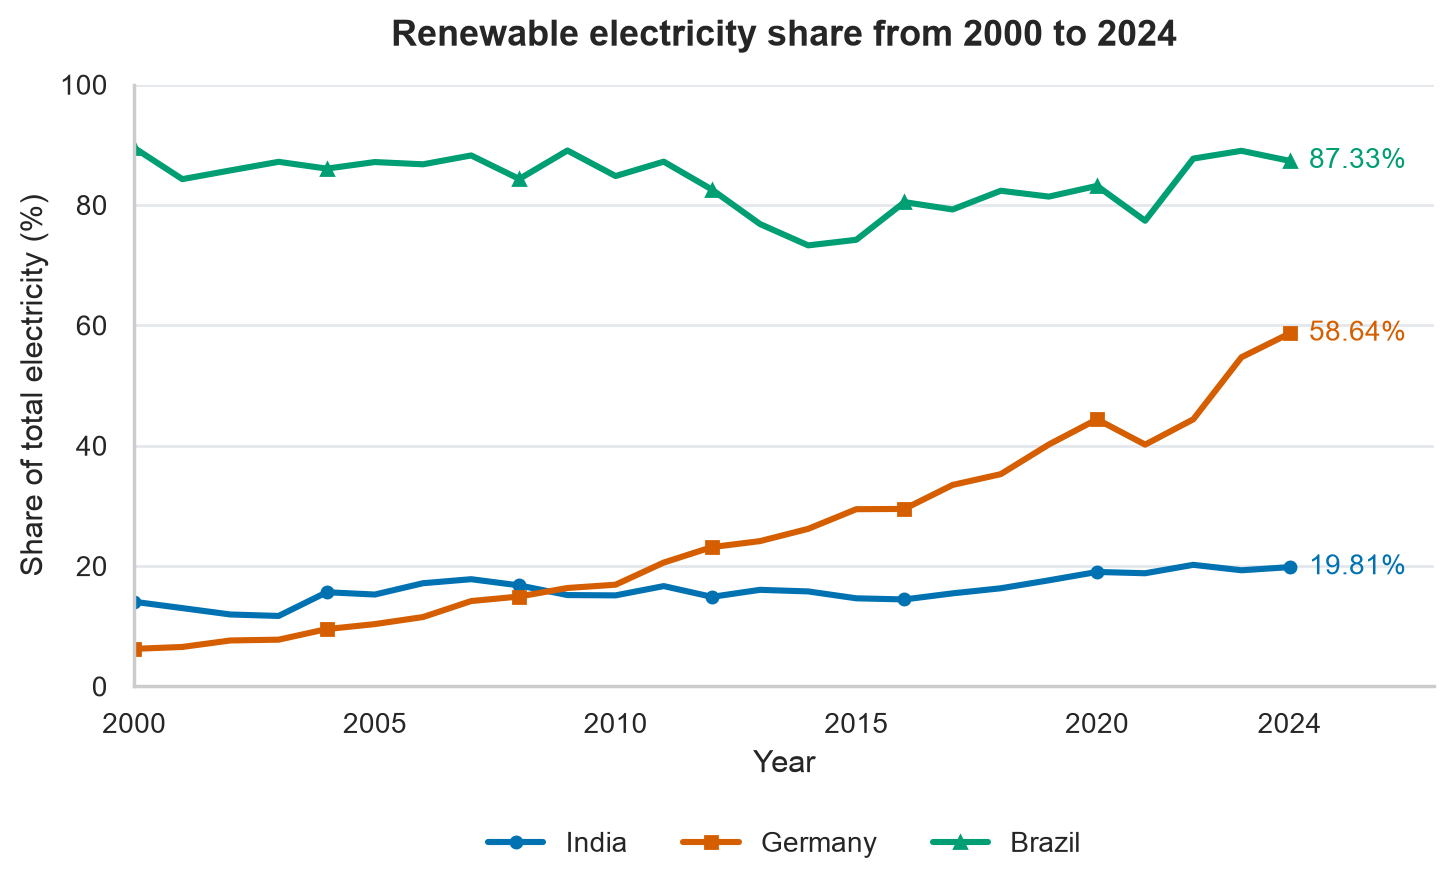

In [6]:
fig, ax = plt.subplots(figsize=(7.4, 4.7))
for country in COUNTRIES:
    country_data = analysis_df.loc[analysis_df["country"].eq(country)].sort_values("year")
    ax.plot(
        country_data["year"], country_data["renewables_electricity_share_pct"],
        label=country, color=COUNTRY_COLORS[country], marker=COUNTRY_MARKERS[country],
        markevery=4, linewidth=2.2, markersize=4,
    )
    value = country_data.iloc[-1]["renewables_electricity_share_pct"]
    ax.annotate(f"{value:.2f}%", (END_YEAR, value), xytext=(7, 0),
                textcoords="offset points", va="center", color=COUNTRY_COLORS[country], fontsize=10)
ax.set_title("Renewable electricity share from 2000 to 2024", fontweight="bold", pad=14)
ax.set_xlabel("Year")
ax.set_ylabel("Share of total electricity (%)")
ax.set_xlim(START_YEAR, END_YEAR + 3)
ax.set_ylim(0, 100)
ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2024])
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

Brazil has the highest renewable share in every study year. Its share falls to 73.28% in 2014 before recovering to 87.33% in 2024. Germany rises from 6.22% to 58.64%, while India's share fluctuates and ends at 19.81%, above its 14.05% starting value. The chart shows that the endpoint changes sit within different annual paths.

### Figure 2. Renewable electricity generation

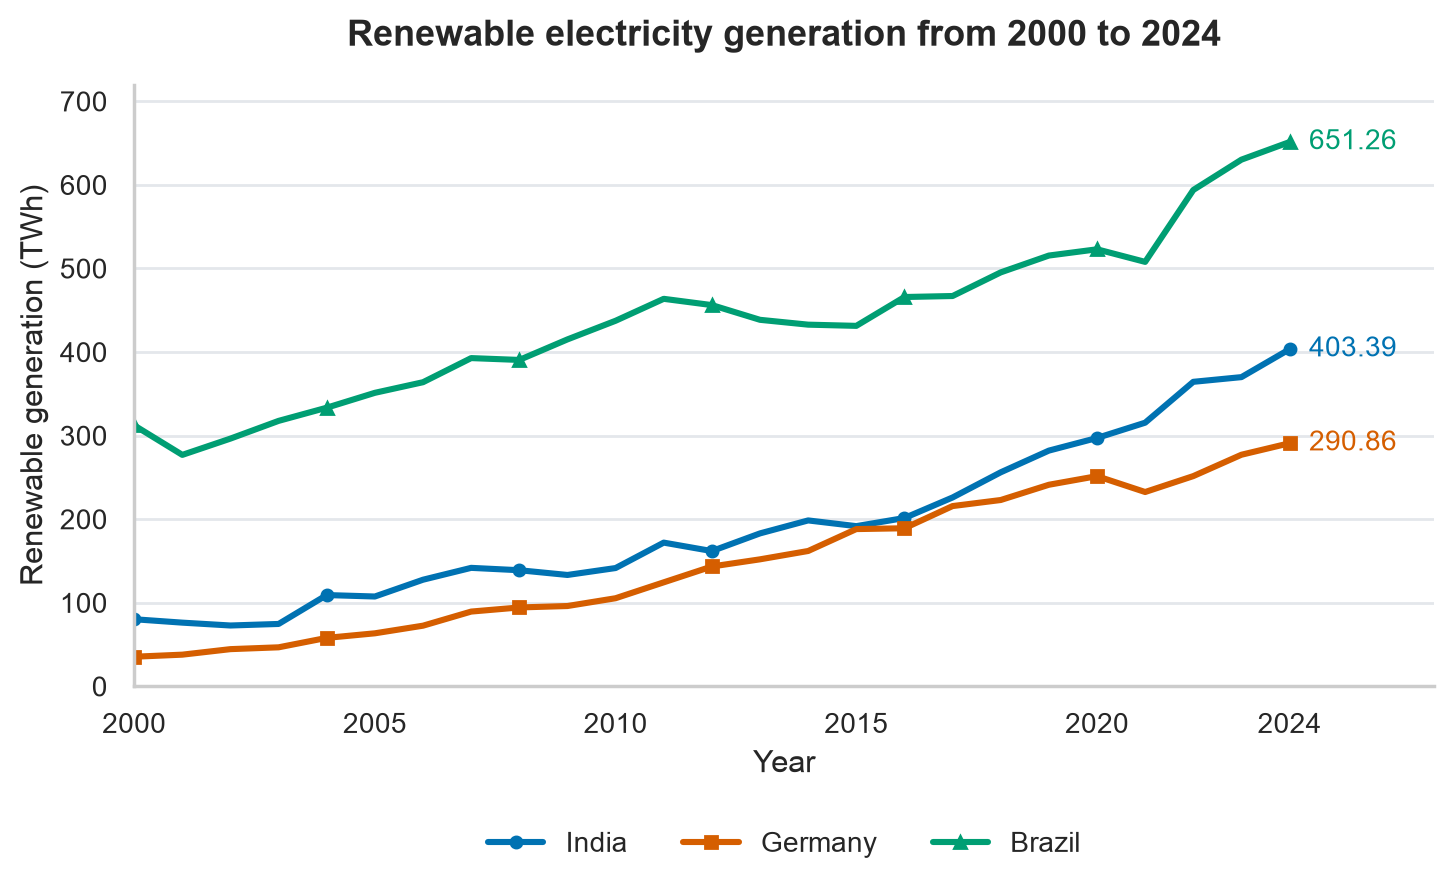

In [7]:
fig, ax = plt.subplots(figsize=(7.4, 4.7))
for country in COUNTRIES:
    country_data = analysis_df.loc[analysis_df["country"].eq(country)].sort_values("year")
    ax.plot(
        country_data["year"], country_data["renewables_electricity_twh"],
        label=country, color=COUNTRY_COLORS[country], marker=COUNTRY_MARKERS[country],
        markevery=4, linewidth=2.2, markersize=4,
    )
    value = country_data.iloc[-1]["renewables_electricity_twh"]
    ax.annotate(f"{value:.2f}", (END_YEAR, value), xytext=(7, 0),
                textcoords="offset points", va="center", color=COUNTRY_COLORS[country], fontsize=10)
ax.set_title("Renewable electricity generation from 2000 to 2024", fontweight="bold", pad=14)
ax.set_xlabel("Year")
ax.set_ylabel("Renewable generation (TWh)")
ax.set_xlim(START_YEAR, END_YEAR + 3)
ax.set_ylim(0, 720)
ax.set_yticks(range(0, 701, 100))
ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2024])
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

Brazil produces the most renewable electricity of the three countries throughout the period, rising from 312.26 to 651.26 TWh. India rises from 80.27 to 403.39 TWh, and Germany from 35.41 to 290.86 TWh. Brazil's output more than doubles even though its renewable share ends slightly lower. The generation table shows that total electricity output also grows, which changes the denominator of the share.

### Figure 3. Renewable source mix

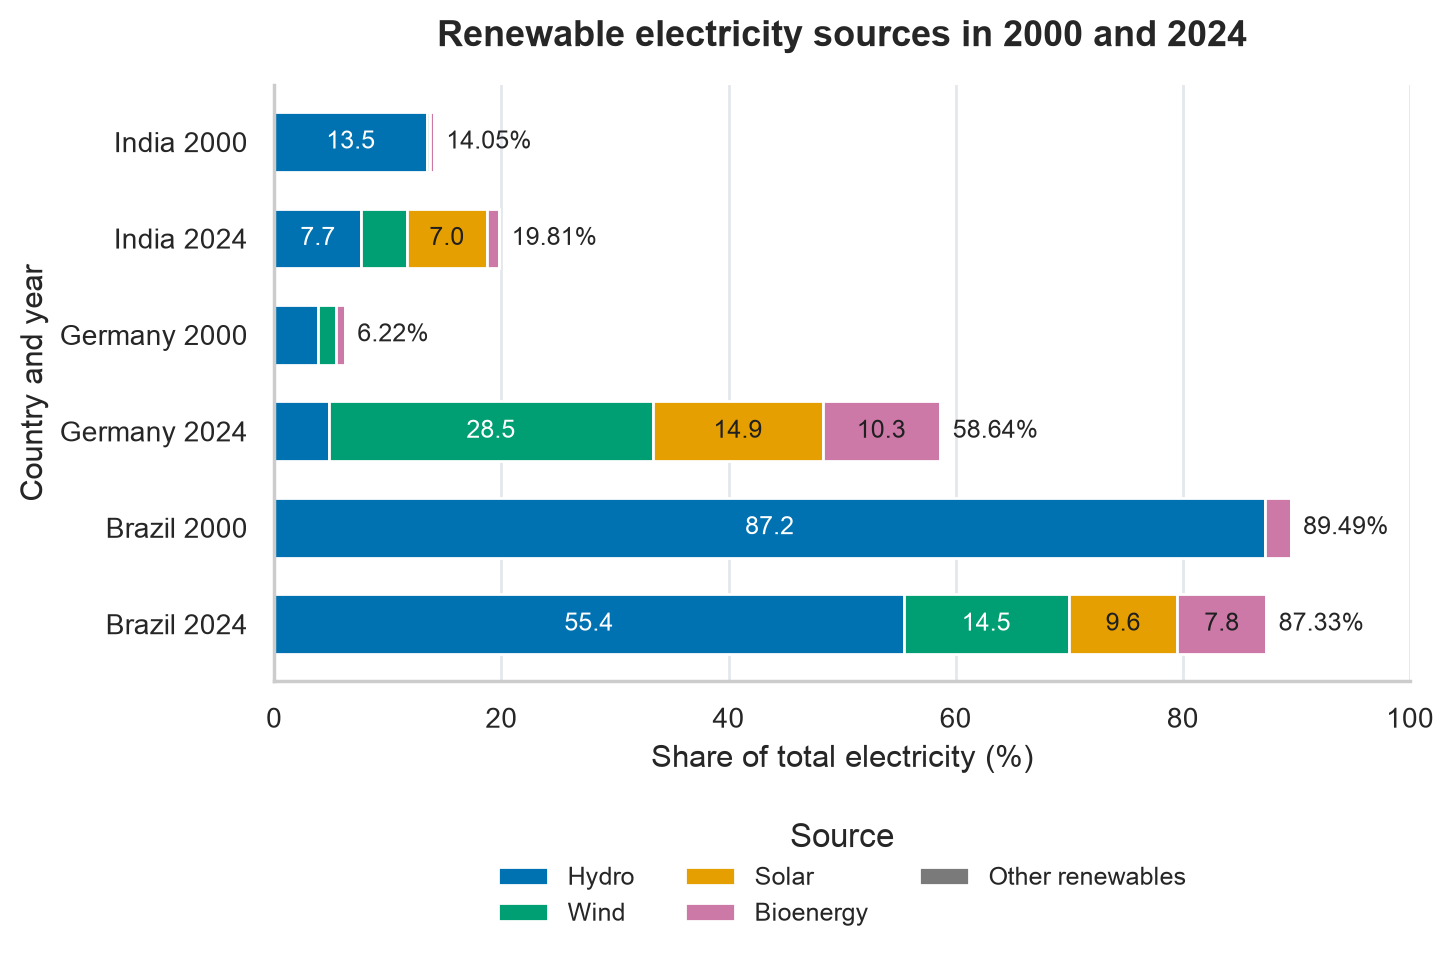

In [8]:
endpoint_keys = pd.MultiIndex.from_product(
    [COUNTRIES, [START_YEAR, END_YEAR]], names=["country", "year"]
)
composition = analysis_df.set_index(["country", "year"]).reindex(endpoint_keys)
row_labels = [f"{country} {year}" for country, year in endpoint_keys]
source_colors = ["#0072B2", "#009E73", "#E69F00", "#CC79A7", "#7A7A7A"]

fig, ax = plt.subplots(figsize=(7.4, 5.1))
left = np.zeros(len(composition))
for (label, column), color in zip(SOURCE_COLUMNS.items(), source_colors):
    values = composition[column].to_numpy()
    ax.barh(row_labels, values, left=left, label=label, color=color, height=0.62)
    for row, (start, value) in enumerate(zip(left, values)):
        if value >= 7:
            ax.text(start + value / 2, row, f"{value:.1f}", ha="center", va="center",
                    fontsize=9, color="white" if label in ["Hydro", "Wind", "Other renewables"] else "#202020")
    left += values
for row, total in enumerate(left):
    ax.text(total + 1.1, row, f"{total:.2f}%", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title("Renewable electricity sources in 2000 and 2024", fontweight="bold", pad=14)
ax.set_xlabel("Share of total electricity (%)")
ax.set_ylabel("Country and year")
ax.grid(axis="y", visible=False)
ax.legend(title="Source", loc="upper center", bbox_to_anchor=(0.5, -0.2),
          ncol=3, frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

Brazil's hydro share falls from 87.24% to 55.41% of total electricity, while wind reaches 14.55% and solar reaches 9.56% in 2024. Germany's largest renewable source in 2024 is wind at 28.55%, followed by solar at 14.95%. In India, hydro at 7.69% and solar at 7.03% account for similar shares by 2024. Wind and solar account for larger shares in 2024 than in 2000 in all three countries, and the bar totals match the overall renewable shares.

The small category called Other renewables excludes bioenergy. Labels inside larger segments show percentage shares, and labels at the bar ends show each country's total renewable share. Values are rounded for display, so printed segment labels can differ slightly from the printed total.

## Summary

Renewable electricity output grows in all three countries, but its share follows different paths. Germany records the largest share increase, moving from 6.22% to 58.64%. India moves from 14.05% to 19.81% as renewable and total electricity output both expand. Brazil remains highest throughout the study and ends at 87.33%, with a lower hydro share and larger wind and solar contributions than in 2000.

The clearest finding is that higher renewable output can occur alongside a slightly lower renewable share. Brazil's renewable generation more than doubles, while total electricity generation grows a little faster. India's renewable share peaks in 2022 rather than the final study year, so the annual chart adds detail that the endpoint table alone would miss.

The analysis assumes that the country boundaries and electricity measures are comparable within this release. All 75 study records have complete values for the selected measures, and no values are filled or estimated. The dataset combines providers and historical series, so future source revisions could change the results. National totals also hide regional differences, and three selected countries cannot represent global trends.

The charts describe the published series. They do not establish why the changes happened or measure cost, grid reliability, energy access, or emissions. The relative roles of policy, weather, demand, and capacity changes remain unclear without further data. A useful next step would compare those factors with the annual electricity series and check the provider notes before making causal claims.